# Etapa 3 — Qualidade das Projeções do Focus

Este notebook responde a pergunta central do projeto: **quão boas são as projeções do boletim Focus, e onde elas falham?** Trabalha sobre os cinco painéis da Etapa 2 (IPCA, Câmbio, IGP-M, Taxa de desocupação, Selic), que cobrem propositalmente regimes de previsibilidade muito diferentes.

A avaliação tem **duas metades**, e a segunda é a novidade que reorienta o projeto:

- **Primeiro momento — o ponto.** O erro é enviesado? O Focus bate "não prever mudança"? É eficiente no sentido de Mincer-Zarnowitz? Reage devagar?
- **Segundo momento — a incerteza.** O boletim publica não só uma mediana, mas também um desvio-padrão, mínimo/máximo e Top 5. **Essa dispersão é uma medida honesta da incerteza da projeção?** Discordância entre analistas e incerteza sobre o futuro são coisas diferentes; a literatura sugere que a primeira subestima a segunda, mas isso raramente é testado.

A Etapa 4 mostrou que o ponto do Focus é difícil de corrigir. Esta etapa mostra por que **o valor está no segundo momento**.

## Roteiro

1. Cobertura e qualidade dos dados
2. Trajetória: realizado vs. previsto
3. Erro por horizonte e o benchmark ingênuo
4. Erro por regime macroeconômico
5. Significância do viés (Newey-West)
6. Eficiência — Mincer-Zarnowitz
7. Autocorrelação dos erros
8. **Calibração da dispersão do Focus** ★
9. Conclusões

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf

RAIZ_PROJETO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ_PROJETO / "src"))

from focus.configuracao import DIR_PROCESSADO, DIR_BRUTO, HORIZONTES_MESES, INDICADORES_MENSAIS, SERIES_SGS
from focus.armazenamento import carregar_dataset
from focus.benchmark import previsao_ingenua_mensal, previsao_ingenua_selic, razao_mae
from focus.calibracao import avaliar_intervalo, pit_normal, teste_uniformidade_pit

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

ORDEM = ["ipca", "cambio", "igpm", "desocupacao", "selic"]
ROTULO = {"ipca": "IPCA", "cambio": "Câmbio", "igpm": "IGP-M", "desocupacao": "Desocupação", "selic": "Selic"}
COR_H = {1: "#2a6f97", 3: "#52b788", 6: "#f4a261", 12: "#a63446"}
COL_DATA = {n: "referencia_periodo" for n in ORDEM} | {"selic": "data_reuniao"}

paineis = {n: carregar_dataset(DIR_PROCESSADO, f"painel_{n}") for n in ORDEM}
for n in ORDEM:
    print(f"{ROTULO[n]:<12} {len(paineis[n]):>4} linhas | {paineis[n][COL_DATA[n]].min():%Y-%m} -> {paineis[n][COL_DATA[n]].max():%Y-%m}")

IPCA          970 linhas | 2006-02 -> 2026-08
Câmbio        970 linhas | 2006-02 -> 2026-08
IGP-M         970 linhas | 2006-02 -> 2026-08
Desocupação   214 linhas | 2021-10 -> 2026-07
Selic         648 linhas | 2006-03 -> 2026-09


## 1. Cobertura e qualidade dos dados

Antes de concluir qualquer coisa: o quanto confiar em cada painel? Dois pontos merecem atenção explícita porque afetam a interpretação de tudo o que segue.

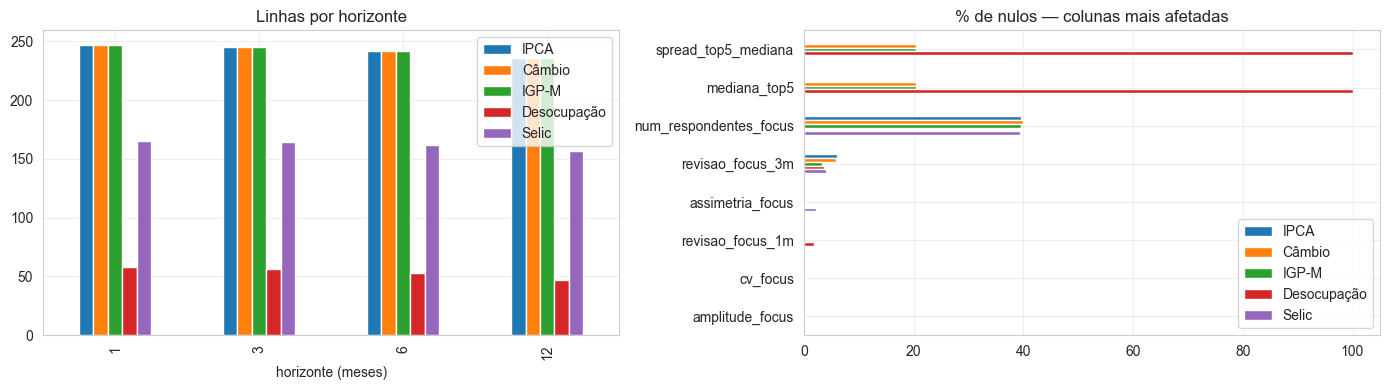

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

contagem = pd.DataFrame({ROTULO[n]: paineis[n].groupby("horizonte").size() for n in ORDEM})
contagem.plot(kind="bar", ax=axes[0])
axes[0].set_title("Linhas por horizonte")
axes[0].set_xlabel("horizonte (meses)")

nulos = pd.DataFrame({ROTULO[n]: paineis[n].isna().mean() * 100 for n in ORDEM})
pior = nulos.max(axis=1).sort_values(ascending=False).head(8).index
nulos.loc[pior].plot(kind="barh", ax=axes[1])
axes[1].set_title("% de nulos — colunas mais afetadas")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

**Duas limitações estruturais, ambas reais e não erros de extração:**

1. **Taxa de desocupação tem amostra curta** — só **214 linhas, de 2021-10 em diante**. A série PNADC do SGS começa em 2012, mas o Focus só passou a projetá-la mensalmente em set/2021. O período é dominado pela queda pós-COVID (12,1% → 5,3% no período), uma tendência forte e monótona. Toda conclusão sobre desocupação vale para esse regime e **não deve ser generalizada**.
2. **O Focus não publica Top 5 para desocupação**, e publica cobertura parcial (~80%) para Câmbio e IGP-M. `spread_top5_mediana` fica `NaN` onde não existe.

## 2. Trajetória: realizado vs. previsto

Para cada horizonte `h`, a linha colorida é a mediana do Focus prevista `h` meses antes, posicionada na data do **alvo** — assim fica diretamente sobreposta ao realizado (linha preta). Quanto mais um horizonte "atrasa" em relação ao preto nos pontos de virada, mais adaptativo foi o consenso.

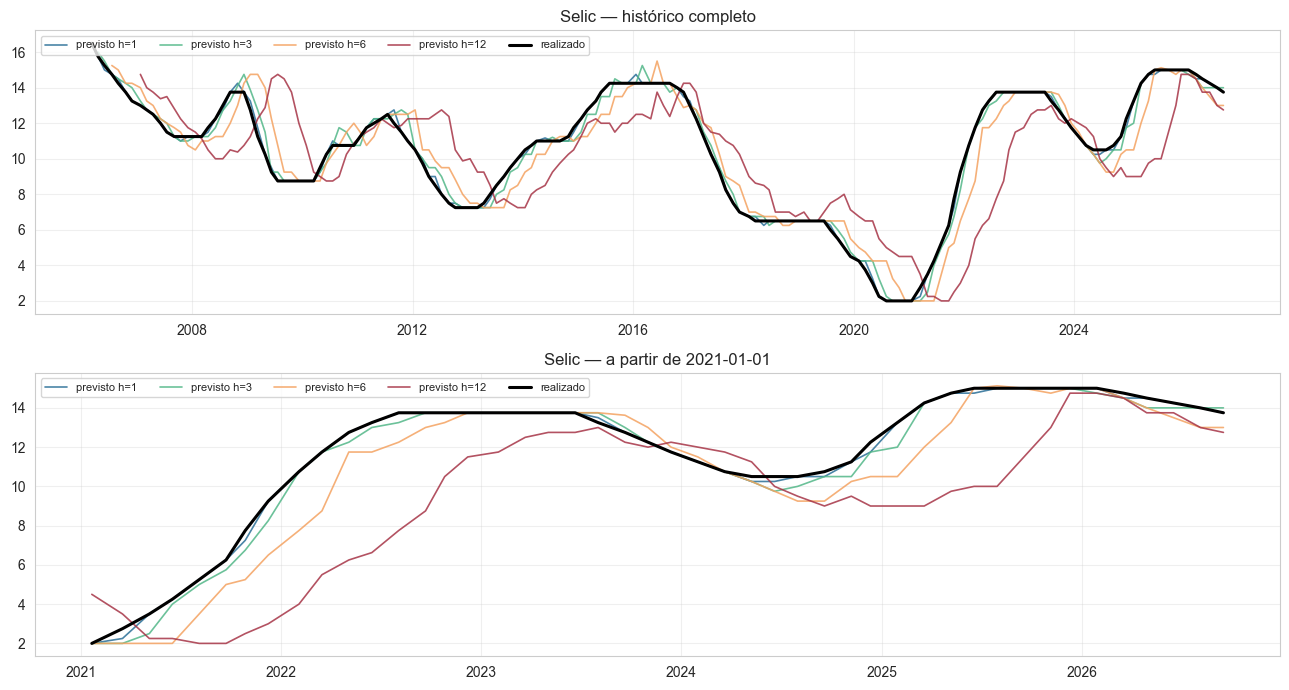

In [3]:
def plotar_trajetoria(nome, inicio_zoom):
    p = paineis[nome]
    col = COL_DATA[nome]
    real = p[[col, "realizado"]].drop_duplicates(subset=[col]).sort_values(col)

    fig, (ax_full, ax_zoom) = plt.subplots(2, 1, figsize=(13, 7))
    for ax, corte in [(ax_full, None), (ax_zoom, pd.Timestamp(inicio_zoom))]:
        for h in HORIZONTES_MESES:
            sub = p.loc[p["horizonte"] == h].sort_values(col)
            if corte is not None:
                sub = sub.loc[sub[col] >= corte]
            ax.plot(sub[col], sub["mediana_focus"], color=COR_H[h], linewidth=1.2, alpha=0.85, label=f"previsto h={h}")
        r = real if corte is None else real.loc[real[col] >= corte]
        ax.plot(r[col], r["realizado"], color="black", linewidth=2.2, label="realizado")
        ax.legend(fontsize=8, ncol=5, loc="upper left")
    ax_full.set_title(f"{ROTULO[nome]} — histórico completo")
    ax_zoom.set_title(f"{ROTULO[nome]} — a partir de {inicio_zoom}")
    plt.tight_layout()
    plt.show()


plotar_trajetoria("selic", "2021-01-01")

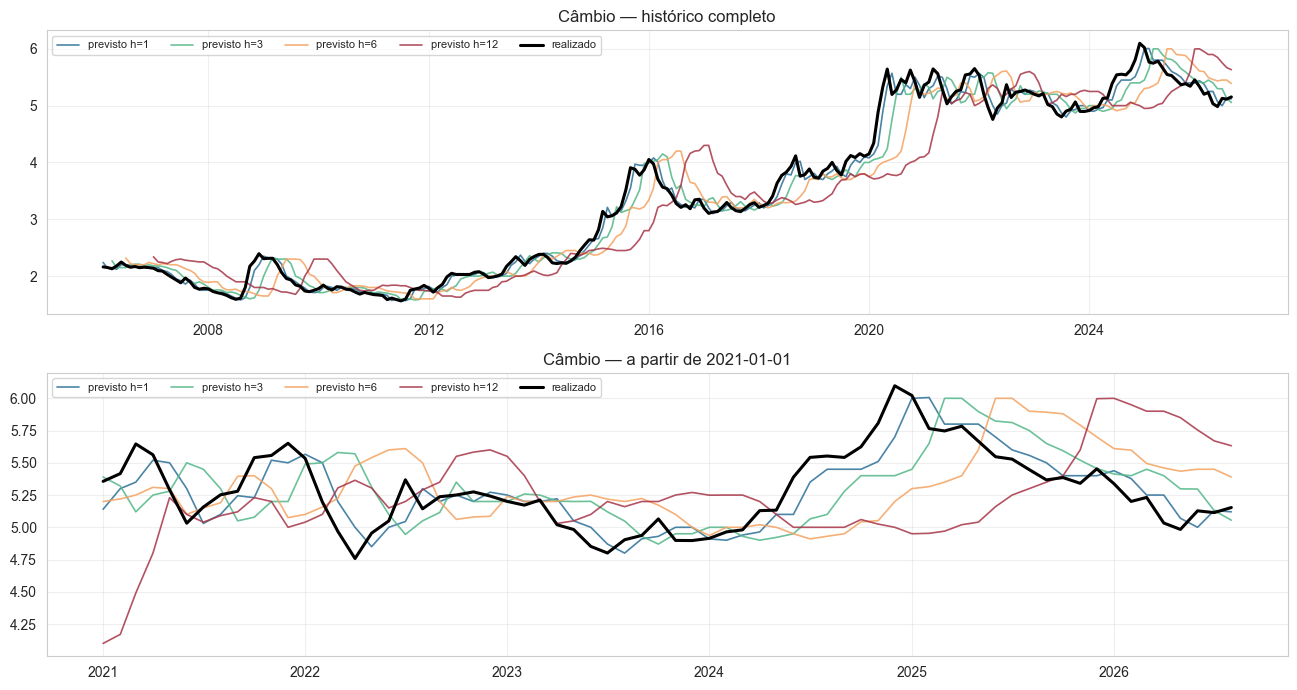

In [4]:
plotar_trajetoria("cambio", "2021-01-01")

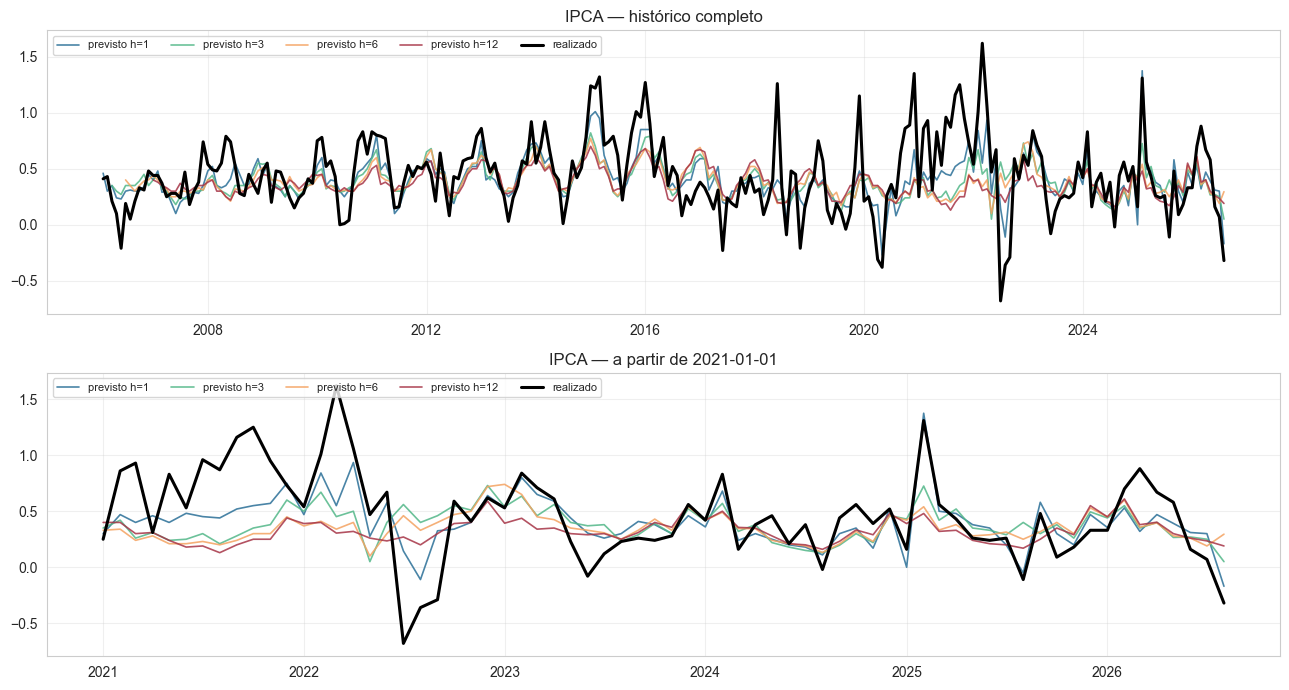

In [5]:
plotar_trajetoria("ipca", "2021-01-01")

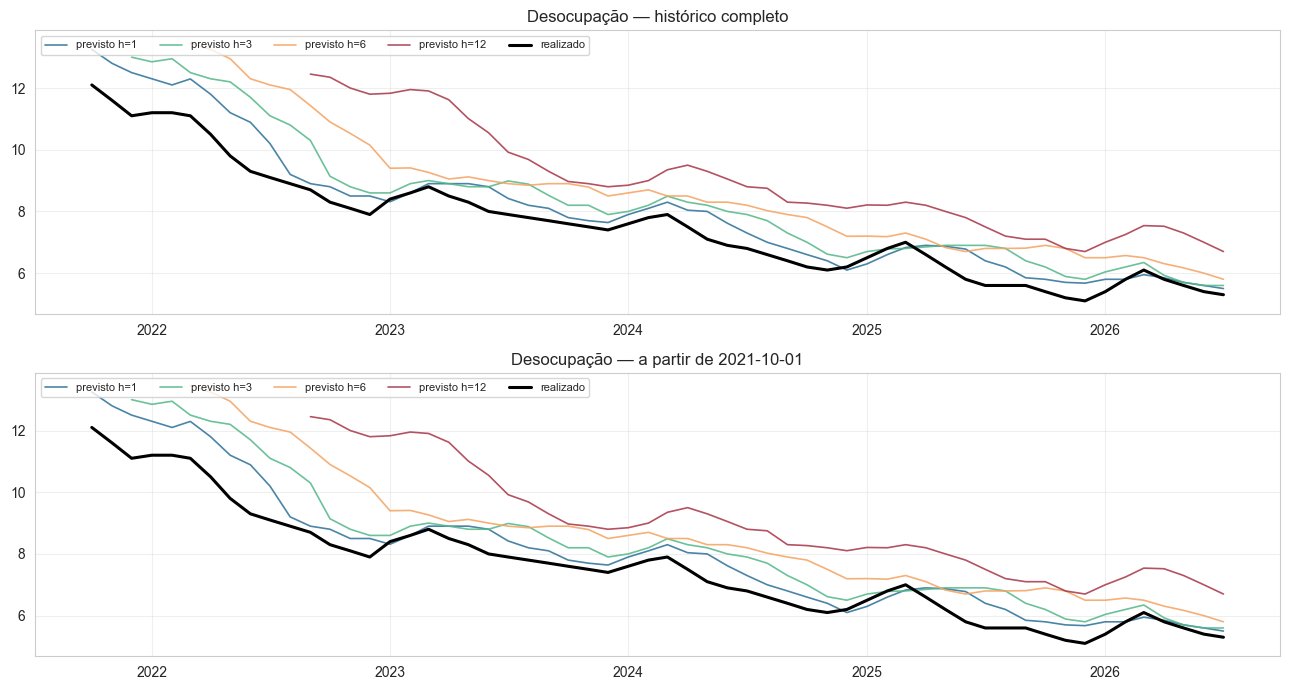

In [6]:
plotar_trajetoria("desocupacao", "2021-10-01")

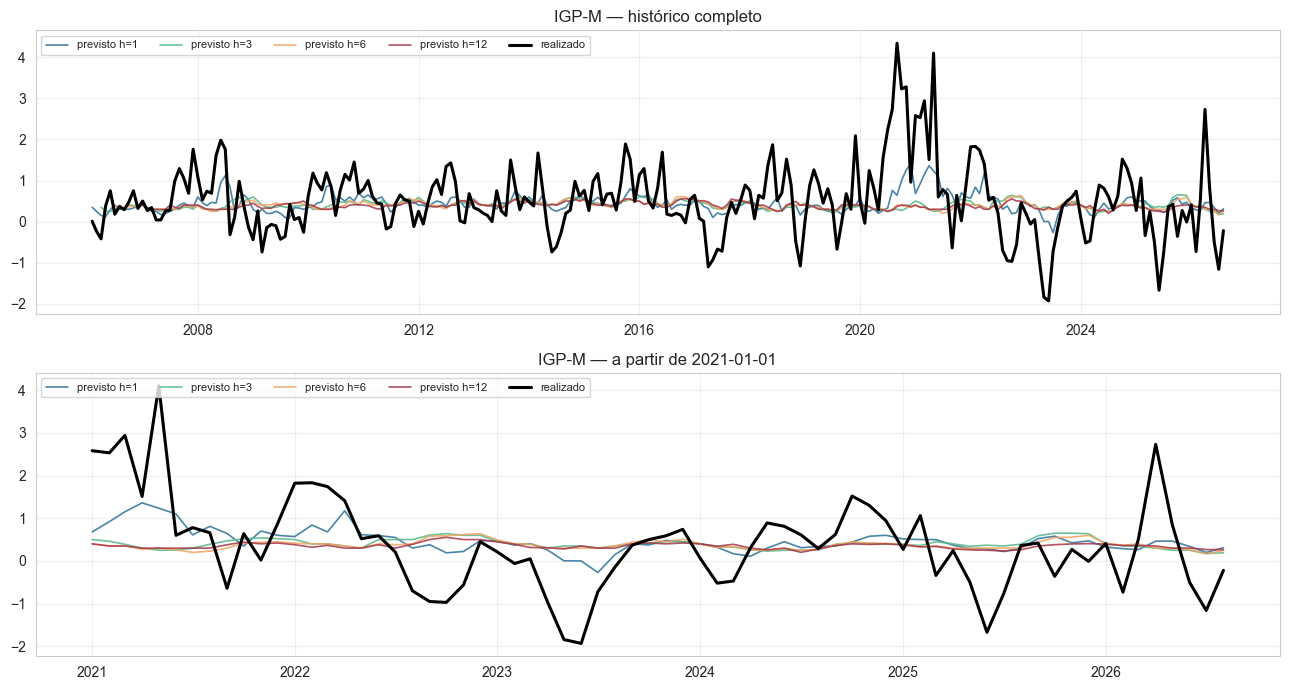

In [7]:
plotar_trajetoria("igpm", "2021-01-01")

A **Selic** mostra o padrão mais nítido: a linha `h=12` atrasa em todo ciclo (2008, 2013, 2015, o aperto de 2021-22, o pivot de 2025-26). No **Câmbio**, as linhas não são planas — acompanham o formato do realizado, mas **com um atraso que cresce com o horizonte**: a linha `h=12` praticamente reproduz o valor observado cerca de um ano antes (veja a disparada de 2016 e a de 2020, que o vermelho só alcança meses depois). É exatamente o comportamento de um passeio aleatório — "amanhã será igual a hoje" — e é por isso que a razão vs. ingênuo chega a 0,99. Na **desocupação**, todos os horizontes ficam acima do realizado durante toda a queda, e a distância **cresce com o horizonte** (o `h=12` chega a ~3 p.p. de erro): o consenso "não acreditou" na melhora do mercado de trabalho.

## 3. Erro por horizonte e o benchmark ingênuo

**Convenção de sinal:** `erro = realizado − mediana`. Erro positivo = o Focus **subestimou**.

**O benchmark ingênuo importa, e precisa ser justo.** "Não prever mudança" só é uma régua válida se usar a mesma informação que o analista tinha: o último valor **já publicado** na `data_travamento` (`src/focus/benchmark.py`, com teste). Um benchmark que use `realizado(P−h)` dá ao analista uma informação que ele não tinha — e, para a Taxa de desocupação, que sai com ~60 dias de defasagem, isso inverte a conclusão (razão 2,19 com o benchmark injusto contra 0,79 com o justo).

In [8]:
def calcular_razoes():
    linhas = []
    for n in ORDEM:
        for h in HORIZONTES_MESES:
            sub = paineis[n].loc[paineis[n]["horizonte"] == h]
            if n == "selic":
                ing = previsao_ingenua_selic(sub)
            else:
                cfg = next(c for c in INDICADORES_MENSAIS.values() if c["nome"] == n)
                real_df = carregar_dataset(DIR_BRUTO, f"sgs_{SERIES_SGS[cfg['sgs']][0]}")
                ing = previsao_ingenua_mensal(sub, real_df, cfg["regra"])
            e = sub["erro_focus"]
            linhas.append({
                "indicador": ROTULO[n], "horizonte": h, "n": len(sub),
                "ME (viés)": e.mean(), "MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()),
                "razão vs ingênuo": razao_mae(e, sub["realizado"], ing),
            })
    return pd.DataFrame(linhas).set_index(["indicador", "horizonte"])


tabela_erros = calcular_razoes()
display(tabela_erros.round(3))

n  ME (viés)    MAE   RMSE  razão vs ingênuo
indicador   horizonte                                                
IPCA        1          247      0.044  0.171  0.237             0.592
            3          245      0.054  0.224  0.311             0.637
            6          242      0.065  0.235  0.324             0.654
            12         236      0.082  0.243  0.331             0.711
Câmbio      1          247      0.019  0.091  0.130             0.640
            3          245      0.040  0.184  0.267             0.862
            6          242      0.066  0.289  0.391             0.954
            12         236      0.130  0.433  0.564             0.990
IGP-M       1          247      0.077  0.544  0.763             0.765
            3          245      0.120  0.631  0.896             0.787
            6          242      0.130  0.632  0.895             0.770
            12         236      0.147  0.640  0.904             0.649
Desocupação 1           58     -0.491  0.522  0.654             0.789
            3           56     -0.837  0.845  1.029             1.009
            6           53     -1.307  1.307  1.519             1.253
            12          47     -2.054  2.054  2.193             1.225
Selic       1          165     -0.007  0.077  0.168             0.203
            3          164     -0.025  0.312  0.476             0.399
            6          162      0.047  0.859  1.160             0.567
            12         157      0.276  2.090  2.647             0.773

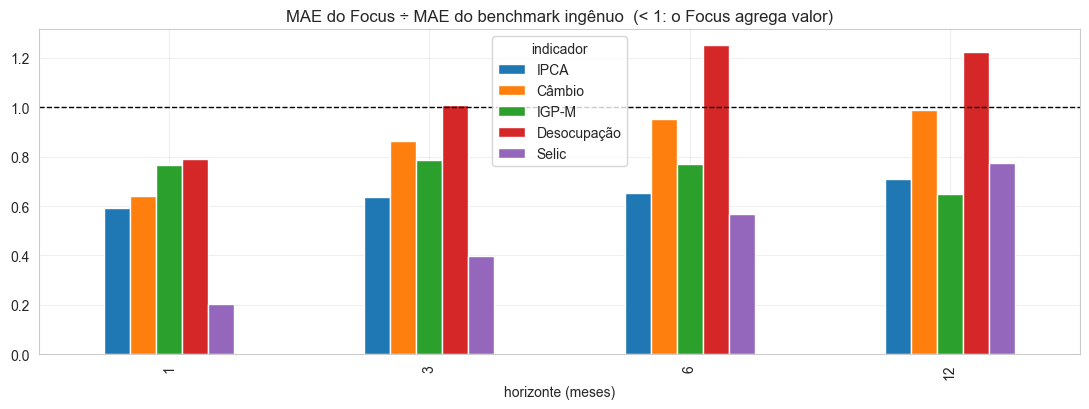

In [9]:
razao = tabela_erros["razão vs ingênuo"].unstack("indicador")[[ROTULO[n] for n in ORDEM]]

fig, ax = plt.subplots(figsize=(11, 4.2))
razao.plot(kind="bar", ax=ax)
ax.axhline(1.0, color="black", linestyle="--", linewidth=1)
ax.set_title("MAE do Focus ÷ MAE do benchmark ingênuo  (< 1: o Focus agrega valor)")
ax.set_xlabel("horizonte (meses)")
plt.tight_layout()
plt.show()

**Leitura.** O Focus agrega valor onde há informação (IPCA, Selic, IGP-M em todos os horizontes) e **converge para o passeio aleatório conforme o horizonte cresce no Câmbio** (razão 0,64 → 0,99) — a confirmação clássica de Meese-Rogoff. A Taxa de desocupação em `h ≥ 6` perde para o ingênuo, mas sobre uma amostra curta e dominada por uma tendência única; é um indício, não uma conclusão.

## 4. Erro por regime macroeconômico

Classificamos cada linha num sub-período de política monetária, pela data do evento-alvo. A taxonomia cobre a amostra inteira, com rótulos de transição entre os regimes nomeados.

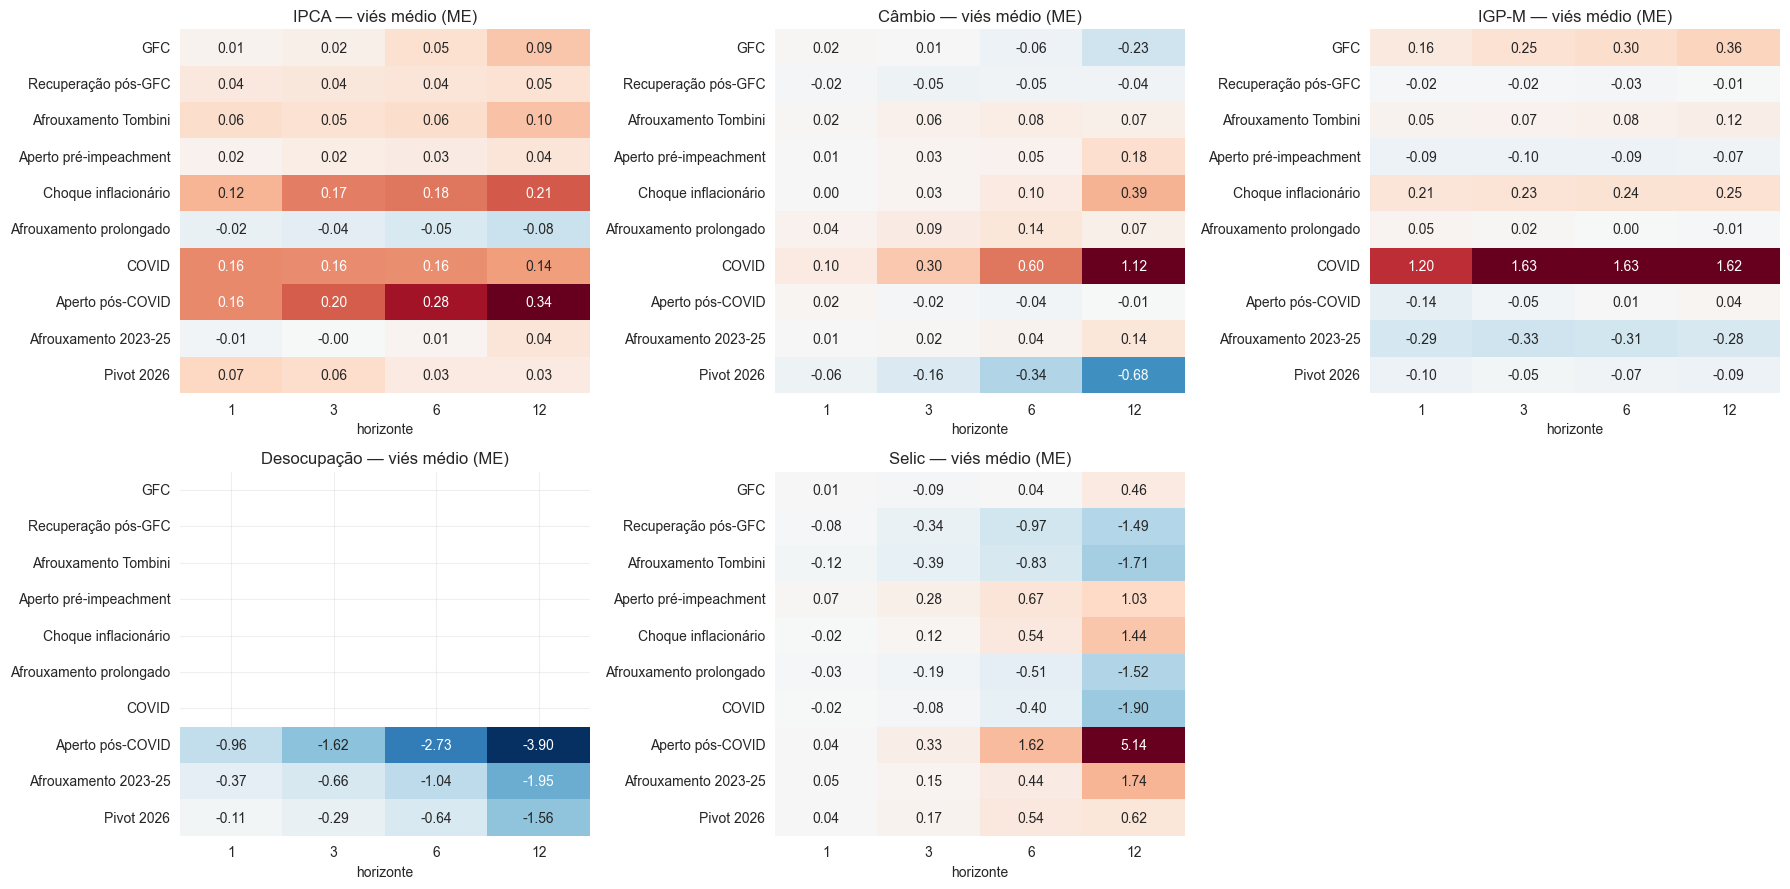

In [10]:
REGIMES = [
    ("2006-01-01", "2008-12-31", "GFC"),
    ("2009-01-01", "2010-12-31", "Recuperação pós-GFC"),
    ("2011-01-01", "2012-12-31", "Afrouxamento Tombini"),
    ("2013-01-01", "2014-12-31", "Aperto pré-impeachment"),
    ("2015-01-01", "2016-12-31", "Choque inflacionário"),
    ("2017-01-01", "2019-12-31", "Afrouxamento prolongado"),
    ("2020-01-01", "2021-06-30", "COVID"),
    ("2021-07-01", "2022-12-31", "Aperto pós-COVID"),
    ("2023-01-01", "2025-12-31", "Afrouxamento 2023-25"),
    ("2026-01-01", "2099-12-31", "Pivot 2026"),
]
ORDEM_REG = [r[2] for r in REGIMES]


def classificar(data):
    for ini, fim, rot in REGIMES:
        if pd.Timestamp(ini) <= data <= pd.Timestamp(fim):
            return rot
    return "outro"


for n in ORDEM:
    paineis[n]["regime_macro"] = pd.Categorical(
        paineis[n][COL_DATA[n]].apply(classificar), categories=ORDEM_REG, ordered=True)

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, n in zip(axes.ravel(), ORDEM):
    piv = (paineis[n].groupby(["regime_macro", "horizonte"], observed=True)["erro_focus"]
           .mean().unstack("horizonte").reindex(ORDEM_REG))
    sns.heatmap(piv, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=ax, cbar=False)
    ax.set_title(f"{ROTULO[n]} — viés médio (ME)")
    ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

**Leitura esperada:** regimes de virada (COVID, aperto pós-COVID, pivot 2026) devem concentrar os maiores vieses absolutos, especialmente em `h=12` — a assinatura de um consenso que reage devagar a mudanças bruscas de regime.

## 5. Significância do viés (Newey-West)

Testamos, por indicador e horizonte, se o viés médio é diferente de zero, com erros-padrão **HAC/Newey-West**. Isso é necessário porque erros de projeção em `h` passos são autocorrelacionados até a defasagem `h−1` mesmo sob eficiência plena; ignorar isso infla a significância. Usamos `maxlags = h` como limite conservador.

In [11]:
def testar_vies(n):
    col = COL_DATA[n]
    linhas = []
    for h in HORIZONTES_MESES:
        sub = paineis[n].loc[paineis[n]["horizonte"] == h].sort_values(col)
        y = sub["erro_focus"].to_numpy()
        m = sm.OLS(y, np.ones_like(y)).fit(cov_type="HAC", cov_kwds={"maxlags": h})
        linhas.append({"indicador": ROTULO[n], "horizonte": h, "n": len(y),
                       "viés": m.params[0], "t (NW)": m.tvalues[0], "p-valor": m.pvalues[0],
                       "signif. 5%": "✔" if m.pvalues[0] < 0.05 else ""})
    return pd.DataFrame(linhas)


tab_vies = pd.concat([testar_vies(n) for n in ORDEM]).set_index(["indicador", "horizonte"])
display(tab_vies.round(4))

n    viés  t (NW)  p-valor signif. 5%
indicador   horizonte                                         
IPCA        1          247  0.0443  2.5577   0.0105          ✔
            3          245  0.0540  1.9007   0.0573           
            6          242  0.0649  1.9313   0.0534           
            12         236  0.0825  2.1326   0.0330          ✔
Câmbio      1          247  0.0186  1.9602   0.0500          ✔
            3          245  0.0396  1.4277   0.1534           
            6          242  0.0663  1.1970   0.2313           
            12         236  0.1303  1.2648   0.2060           
IGP-M       1          247  0.0774  1.3085   0.1907           
            3          245  0.1204  1.3254   0.1850           
            6          242  0.1300  1.2086   0.2268           
            12         236  0.1466  1.1614   0.2455           
Desocupação 1           58 -0.4908 -6.4145   0.0000          ✔
            3           56 -0.8372 -5.8056   0.0000          ✔
            6           53 -1.3073 -5.6334   0.0000          ✔
            12          47 -2.0540 -7.3575   0.0000          ✔
Selic       1          165 -0.0071 -0.5194   0.6035           
            3          164 -0.0254 -0.4395   0.6603           
            6          162  0.0473  0.2453   0.8062           
            12         157  0.2759  0.5096   0.6103

## 6. Eficiência — regressões de Mincer-Zarnowitz

Regredimos o realizado contra a previsão: `Realizado = α + β·Focus + ε`. Sob eficiência, `α=0` **e** `β=1`. `β<1` sinaliza **sub-reação** (o Focus se move menos que o realizado — assinatura de consenso adaptativo); `β>1`, amplificação. O teste de Wald conjunto usa covariância HAC.

**Cuidado com a interpretação em séries persistentes.** Para Selic e Câmbio, o nível é altamente persistente e o R² é dominado por essa persistência; `β` fica próximo de 1 quase mecanicamente. Vale ler o `β` junto com a razão vs. ingênuo da seção 3.

In [12]:
def mincer(n):
    linhas = []
    for h in HORIZONTES_MESES:
        sub = paineis[n].loc[paineis[n]["horizonte"] == h].sort_values(COL_DATA[n])
        X = sm.add_constant(sub["mediana_focus"].to_numpy())
        m = sm.OLS(sub["realizado"].to_numpy(), X).fit(cov_type="HAC", cov_kwds={"maxlags": h})
        w = m.wald_test("const = 0, x1 = 1", scalar=True)
        linhas.append({"indicador": ROTULO[n], "horizonte": h, "n": len(sub),
                       "alpha": m.params[0], "beta": m.params[1], "R²": m.rsquared,
                       "p Wald(α=0,β=1)": float(w.pvalue),
                       "rejeita 5%": "✔" if float(w.pvalue) < 0.05 else ""})
    return pd.DataFrame(linhas)


tab_mz = pd.concat([mincer(n) for n in ORDEM]).set_index(["indicador", "horizonte"])
display(tab_mz.round(4))

n   alpha    beta      R²  p Wald(α=0,β=1) rejeita 5%
indicador   horizonte                                                         
IPCA        1          247 -0.0643  1.2707  0.5456           0.0001          ✔
            3          245  0.0463  1.0196  0.1761           0.1620           
            6          242  0.1160  0.8675  0.1052           0.1444           
            12         236  0.1104  0.9252  0.1011           0.0989           
Câmbio      1          247  0.0133  1.0016  0.9921           0.0660           
            3          245  0.0629  0.9931  0.9668           0.1882           
            6          242  0.1230  0.9832  0.9298           0.2729           
            12         236  0.2300  0.9702  0.8588           0.2865           
IGP-M       1          247 -0.4911  2.2831  0.3483           0.0000          ✔
            3          245  0.9422 -1.0276  0.0139           0.0464          ✔
            6          242  0.8366 -0.7697  0.0061           0.1309           
            12         236  0.7988 -0.6894  0.0035           0.3074           
Desocupação 1           58  0.7082  0.8513  0.9721           0.0000          ✔
            3           56  0.9881  0.7790  0.9428           0.0000          ✔
            6           53  1.3785  0.6847  0.8908           0.0000          ✔
            12          47  1.4224  0.6109  0.8687           0.0000          ✔
Selic       1          165  0.0174  0.9977  0.9977           0.7263           
            3          164  0.0771  0.9903  0.9811           0.7300           
            6          162  0.4265  0.9635  0.8867           0.8113           
            12         157  2.6343  0.7656  0.4531           0.4273

## 7. Autocorrelação dos erros

Se o Focus fosse plenamente eficiente, o erro em `t` não ajudaria a prever o erro em `t+1` além da autocorrelação mecânica até `h−1`. **Autocorrelação positiva além disso é a assinatura direta de um consenso adaptativo.** A faixa sombreada é o IC de 95% sob ruído branco.

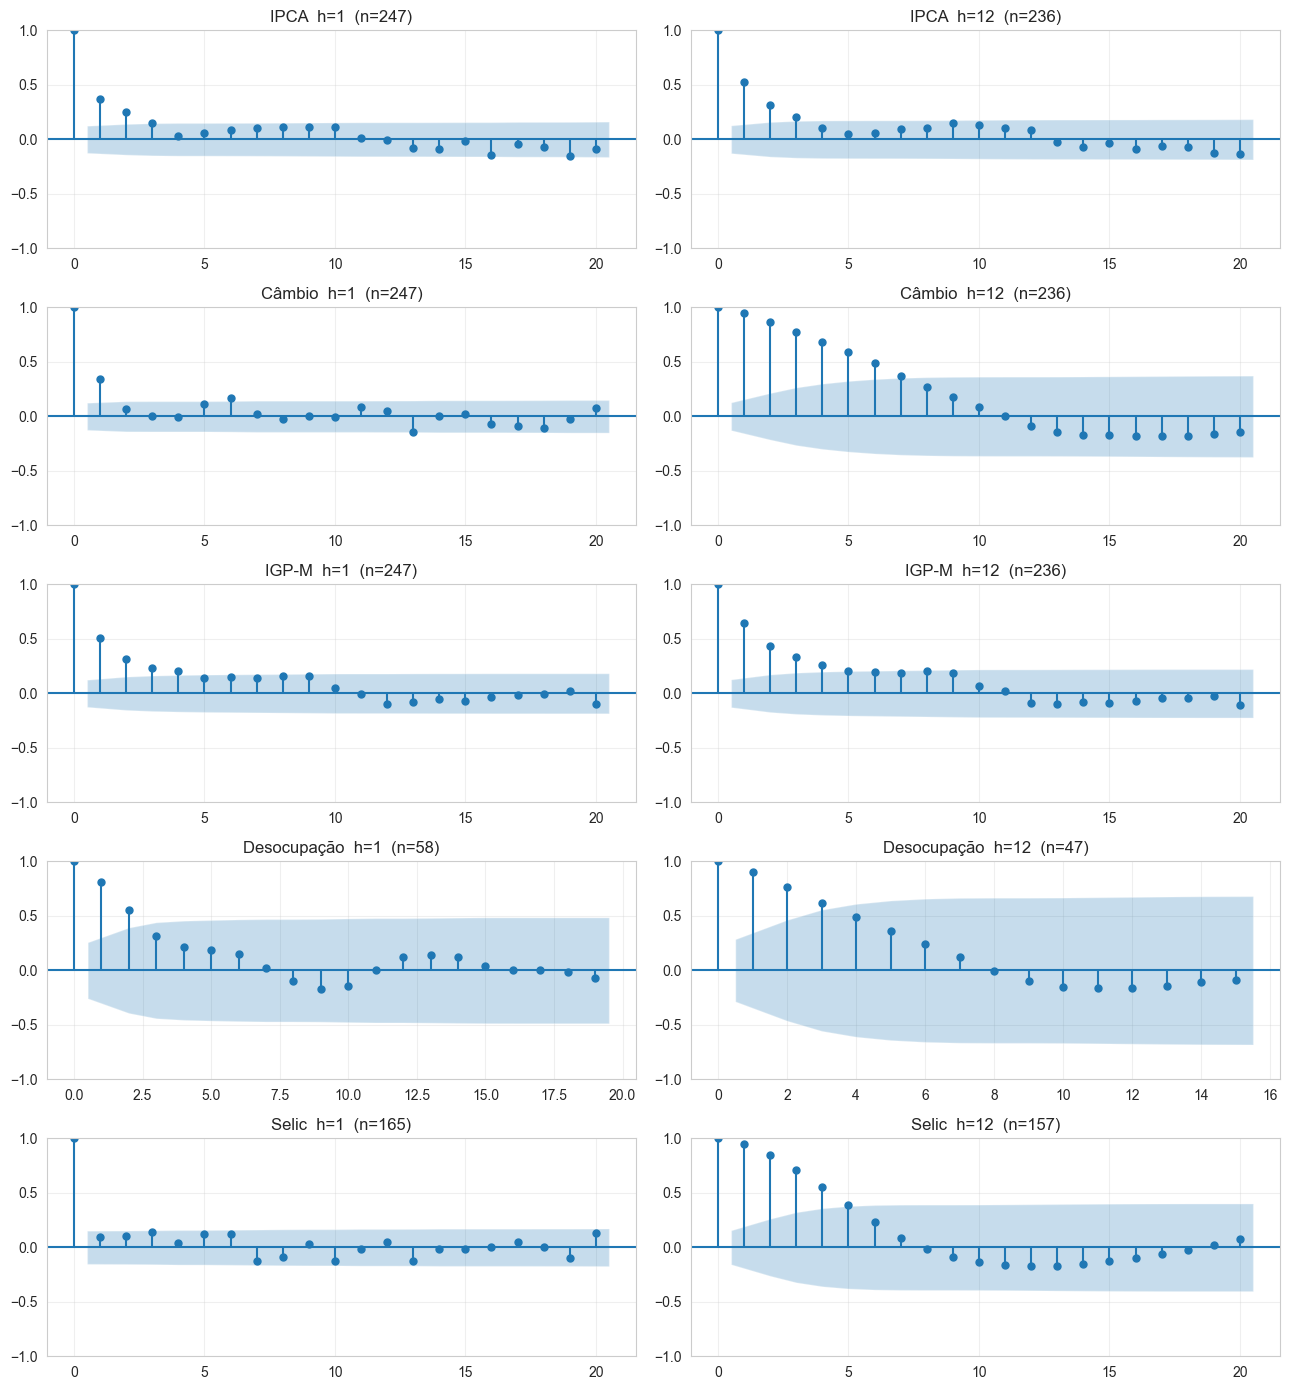

In [13]:
fig, axes = plt.subplots(5, 2, figsize=(13, 14))
for i, n in enumerate(ORDEM):
    for j, h in enumerate([1, 12]):
        sub = paineis[n].loc[paineis[n]["horizonte"] == h].sort_values(COL_DATA[n])
        lags = min(20, len(sub) // 3)
        plot_acf(sub["erro_focus"], ax=axes[i, j], lags=lags, title=f"{ROTULO[n]}  h={h}  (n={len(sub)})")
plt.tight_layout()
plt.show()

## 8. Calibração da dispersão do Focus ★

Esta é a seção que justifica o restante do projeto.

O Focus publica, junto com a mediana, o **desvio-padrão entre analistas**. Um usuário do boletim que quisesse um intervalo em torno da projeção faria o óbvio: `mediana ± z·desvio_padrão`. A pergunta é: **esse intervalo cobre o realizado na frequência que declara?**

Se a dispersão fosse uma medida honesta da incerteza, um intervalo de "90%" deveria conter o realizado em ~90% das vezes. Mas discordância entre analistas e incerteza sobre o futuro **não são a mesma coisa**: os analistas compartilham fontes, modelos e o mesmo boletim anterior, então tendem a concordar entre si *e* errar juntos. A dispersão mede o primeiro fenômeno; o usuário precisa do segundo.

Instrumentos, em ordem crescente de exigência (`src/focus/calibracao.py`, com testes de poder — incluindo um que garante que um intervalo estreito demais **é** detectado):
- **Cobertura empírica** vs. nominal
- **Kupiec**: a taxa de violação bate com a nominal?
- **Christoffersen**: as violações são independentes, ou se agrupam?
- **PIT**: a densidade inteira está calibrada?

In [14]:
NIVEIS = [0.50, 0.80, 0.90, 0.95]


def cobertura_focus(n, h):
    '''Cobertura empirica do intervalo implicito Normal(mediana, desvio_padrao).'''
    col = COL_DATA[n]
    sub = paineis[n].loc[(paineis[n]["horizonte"] == h) & (paineis[n]["desvio_padrao_focus"] > 0)].sort_values(col)
    y, mu, sd = (sub[c].to_numpy() for c in ("realizado", "mediana_focus", "desvio_padrao_focus"))
    res = {}
    for nv in NIVEIS:
        z = stats.norm.ppf(0.5 + nv / 2)
        res[nv] = avaliar_intervalo(y, mu - z * sd, mu + z * sd, nv)
    return res, (y, mu, sd)


linhas = []
for n in ORDEM:
    for h in HORIZONTES_MESES:
        res, (y, mu, sd) = cobertura_focus(n, h)
        linha = {"indicador": ROTULO[n], "horizonte": h, "n": len(y)}
        for nv in NIVEIS:
            linha[f"cob {int(nv*100)}%"] = res[nv]["cobertura_observada"]
        linha["Kupiec p (90%)"] = res[0.90]["kupiec_p"]
        linha["Christoffersen p (90%)"] = res[0.90]["christoffersen_cc_p"]
        linhas.append(linha)

tab_cob = pd.DataFrame(linhas).set_index(["indicador", "horizonte"])
display(tab_cob.round(3))

n  cob 50%  cob 80%  cob 90%  cob 95%  \
indicador   horizonte                                            
IPCA        1          247    0.283    0.405    0.555    0.628   
            3          245    0.192    0.351    0.457    0.518   
            6          242    0.190    0.335    0.397    0.455   
            12         236    0.186    0.288    0.394    0.436   
Câmbio      1          247    0.417    0.660    0.785    0.858   
            3          245    0.290    0.473    0.567    0.629   
            6          242    0.194    0.314    0.405    0.500   
            12         236    0.123    0.254    0.331    0.390   
IGP-M       1          247    0.162    0.344    0.401    0.462   
            3          245    0.147    0.233    0.286    0.339   
            6          242    0.136    0.223    0.256    0.298   
            12         236    0.131    0.212    0.254    0.297   
Desocupação 1           58    0.276    0.483    0.655    0.724   
            3           56    0.196    0.446    0.482    0.625   
            6           53    0.057    0.189    0.340    0.415   
            12          47    0.000    0.000    0.000    0.043   
Selic       1          154    0.740    0.766    0.818    0.877   
            3          160    0.419    0.581    0.650    0.731   
            6          162    0.235    0.377    0.463    0.519   
            12         157    0.159    0.287    0.363    0.401   

                       Kupiec p (90%)  Christoffersen p (90%)  
indicador   horizonte                                          
IPCA        1                   0.000                   0.000  
            3                   0.000                   0.000  
            6                   0.000                   0.000  
            12                  0.000                   0.000  
Câmbio      1                   0.000                   0.000  
            3                   0.000                   0.000  
            6                   0.000                   0.000  
            12                  0.000                   0.000  
IGP-M       1                   0.000                   0.000  
            3                   0.000                   0.000  
            6                   0.000                   0.000  
            12                  0.000                   0.000  
Desocupação 1                   0.000                   0.000  
            3                   0.000                   0.000  
            6                   0.000                   0.000  
            12                  0.000                   0.000  
Selic       1                   0.002                   0.004  
            3                   0.000                   0.000  
            6                   0.000                   0.000  
            12                  0.000                   0.000

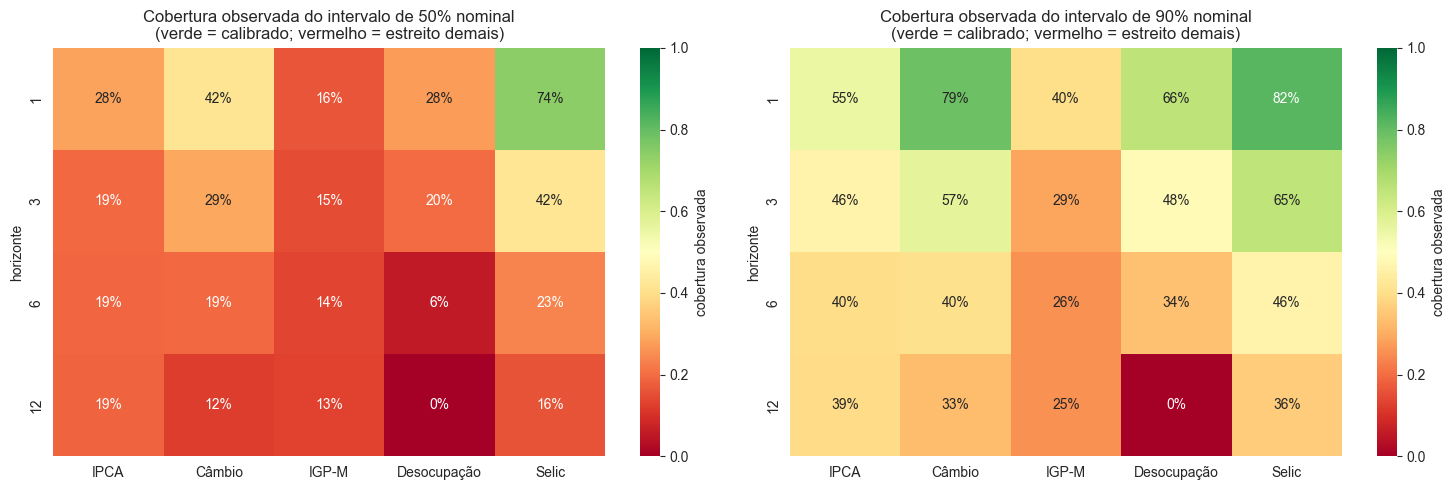

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, nv in zip(axes, [0.50, 0.90]):
    col = f"cob {int(nv*100)}%"
    piv = tab_cob[col].unstack("indicador")[[ROTULO[n] for n in ORDEM]]
    sns.heatmap(piv, annot=True, fmt=".0%", cmap="RdYlGn", vmin=0, vmax=1, ax=ax,
                cbar_kws={"label": "cobertura observada"})
    ax.set_title(f"Cobertura observada do intervalo de {int(nv*100)}% nominal\n(verde = calibrado; vermelho = estreito demais)")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Resultado.** A hipótese se confirma de forma drástica: um intervalo declarado de 90% cobre, na **mediana das 20 combinações indicador × horizonte, apenas 40%** das realizações (mínimo 0%, máximo 82%), e o teste de Kupiec **rejeita a calibração em 20 de 20**. O problema **cresce com o horizonte** — o IPCA cai de 55% em `h=1` para 39% em `h=12`; o Câmbio, de 78% para 33%. Vale para os cinco indicadores (IGP-M 40% → 25%; Selic 82% → 36%; desocupação 66% → 0%). Faz sentido: a discordância entre analistas não cresce com o horizonte na mesma proporção que a incerteza real.

**Um caso merece atenção separada — Selic `h=1`.** O intervalo de 50% cobre **74%** (larga demais no centro), mas o de 90% cobre só **82%** (estreita demais nas caudas). Escala errada não produz esse padrão: é um problema de **forma**. A evidência é direta: **75,8% dos erros de `h=1` da Selic são exatamente zero** — o Copom telegrafa suas decisões e o consenso acerta na mosca, com surpresas raras e grandes. É uma distribuição com massa pontual em zero e caudas pesadas, que a Normal não representa. É também por isso que `k (50%)` aparece como 0 na tabela de fatores abaixo (e a razão `k90/k50` como `inf`): mais da metade dos erros é nula.

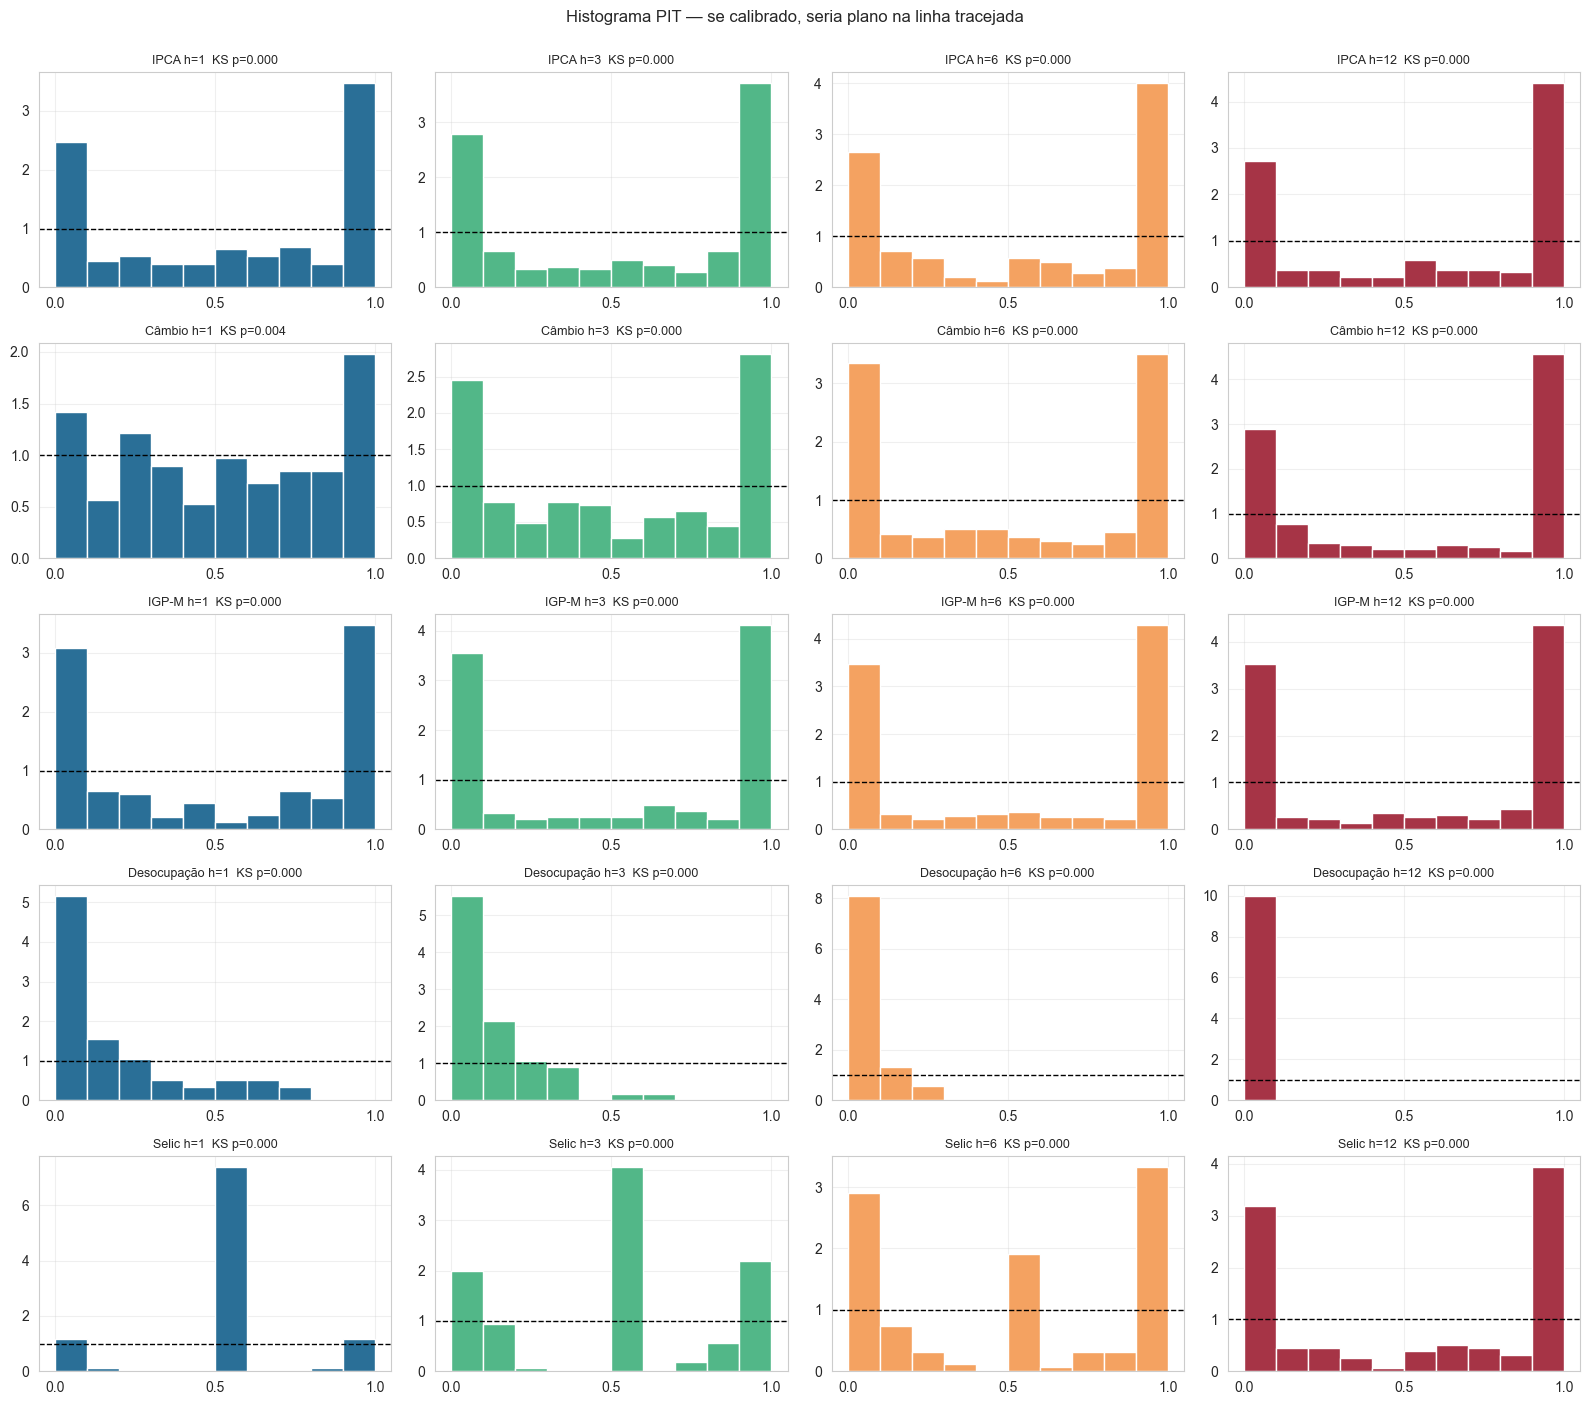

In [16]:
fig, axes = plt.subplots(5, 4, figsize=(16, 14))
for i, n in enumerate(ORDEM):
    for j, h in enumerate(HORIZONTES_MESES):
        _, (y, mu, sd) = cobertura_focus(n, h)
        u = pit_normal(y, mu, sd)
        ks = teste_uniformidade_pit(u)
        ax = axes[i, j]
        ax.hist(u, bins=10, range=(0, 1), color=COR_H[h], edgecolor="white", density=True)
        ax.axhline(1.0, color="black", linestyle="--", linewidth=1)
        ax.set_title(f"{ROTULO[n]} h={h}  KS p={ks['p_valor']:.3f}", fontsize=9)
        ax.set_xticks([0, 0.5, 1])
plt.suptitle("Histograma PIT — se calibrado, seria plano na linha tracejada", y=1.0)
plt.tight_layout()
plt.show()

**Como ler o PIT.** Uniforme (plano) = calibrado. **Acúmulo nas duas pontas** (formato de "U") = densidade estreita demais: o realizado cai com frequência nas caudas que o modelo considerava improváveis. **Assimetria** (barras altas só de um lado) = viés: a previsão erra sistematicamente numa direção — é o caso da desocupação, onde o realizado ficou sistematicamente abaixo do previsto.

### Quanto o intervalo precisaria ser mais largo?

Um número resume a magnitude do problema: o **fator de inflação** `k`, tal que `mediana ± k·z·desvio_padrão` cobriria exatamente o nível nominal. É o quantil empírico de `|erro| / desvio_padrão` dividido pelo quantil normal correspondente. `k = 1` seria calibração perfeita; `k = 3` significa que o intervalo publicado precisaria ser **três vezes mais largo**.

Se `k` for **estável entre níveis nominais** (`k90/k50` próximo de 1), o erro é essencialmente de **escala**; se variar, há também um erro de **forma**.

A tabela mostra que, para IPCA, Câmbio e IGP-M, `k90/k50` fica entre ~1,0 e ~1,5 — o problema é sobretudo de escala, com `k` no nível de 90% entre **1,3 e 7,3** nas 20 combinações (mediana ≈ 3,2): IPCA 2,6–4,2, Câmbio 1,4–4,0, IGP-M 3,2–7,3 (o maior, crescendo com o horizonte), Selic 1,3–4,5 e desocupação 1,5–2,6. O erro de forma é específico da **Selic de curto prazo** (massa em zero) e da **desocupação** (`k90/k50 < 1`: erros todos do mesmo sinal, concentrados — é viés, não dispersão).

In [17]:
linhas = []
for n in ORDEM:
    for h in HORIZONTES_MESES:
        col = COL_DATA[n]
        sub = paineis[n].loc[(paineis[n]["horizonte"] == h) & (paineis[n]["desvio_padrao_focus"] > 0)]
        z_abs = (sub["erro_focus"].abs() / sub["desvio_padrao_focus"]).to_numpy()
        linha = {"indicador": ROTULO[n], "horizonte": h}
        for nv in (0.50, 0.90):
            linha[f"k ({int(nv*100)}%)"] = np.quantile(z_abs, nv) / stats.norm.ppf(0.5 + nv / 2)
        linhas.append(linha)

tab_k = pd.DataFrame(linhas).set_index(["indicador", "horizonte"])
tab_k["k90 / k50"] = tab_k["k (90%)"] / tab_k["k (50%)"]
display(tab_k.round(2))

k (50%)  k (90%)  k90 / k50
indicador   horizonte                             
IPCA        1             2.31     2.64       1.14
            3             2.78     4.21       1.51
            6             3.15     3.95       1.25
            12            3.55     3.78       1.06
Câmbio      1             1.16     1.43       1.23
            3             2.05     2.62       1.28
            6             2.92     3.29       1.13
            12            3.83     4.03       1.05
IGP-M       1             3.08     3.15       1.02
            3             4.45     5.29       1.19
            6             4.60     6.28       1.37
            12            5.26     7.33       1.39
Desocupação 1             1.96     1.52       0.78
            3             2.58     2.10       0.81
            6             3.48     2.43       0.70
            12            4.56     2.62       0.57
Selic       1             0.00     1.32        inf
            3             1.52     1.91       1.25
            6             2.64     3.26       1.23
            12            4.24     4.50       1.06

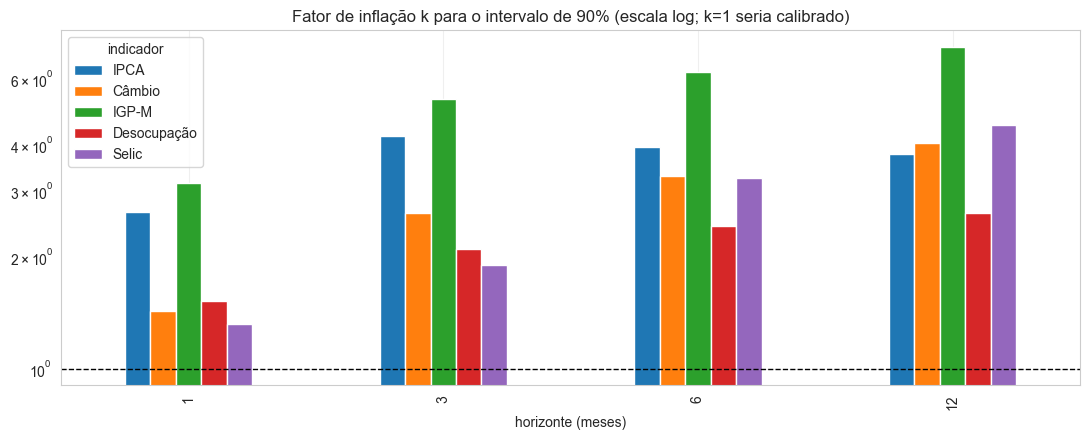

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.5))
piv = tab_k["k (90%)"].unstack("indicador")[[ROTULO[n] for n in ORDEM]]
piv.plot(kind="bar", ax=ax)
ax.axhline(1.0, color="black", linestyle="--", linewidth=1)
ax.set_yscale("log")
ax.set_title("Fator de inflação k para o intervalo de 90% (escala log; k=1 seria calibrado)")
ax.set_xlabel("horizonte (meses)")
plt.tight_layout()
plt.show()

### A dispersão ao menos ordena a incerteza?

Mesmo com a escala errada, a dispersão poderia ser **informativa em termos relativos**: quando os analistas discordam mais, o erro realmente tende a ser maior? Se sim, um simples reescalonamento a salvaria; se não, é preciso modelar a incerteza a partir de outros sinais. Isso decide entre as abordagens da Etapa 5.

Medimos a correlação de Spearman entre `desvio_padrao_focus` e `|erro|`, e o erro absoluto médio por tercil de dispersão.

In [19]:
linhas = []
for n in ORDEM:
    for h in HORIZONTES_MESES:
        sub = paineis[n].loc[(paineis[n]["horizonte"] == h) & (paineis[n]["desvio_padrao_focus"] > 0)]
        rho, p = stats.spearmanr(sub["desvio_padrao_focus"], sub["erro_focus"].abs())
        # razao entre o erro medio do tercil mais disperso e o do menos disperso
        tercil = pd.qcut(sub["desvio_padrao_focus"], 3, labels=["baixa", "média", "alta"], duplicates="drop")
        mae_t = sub.groupby(tercil, observed=True)["erro_focus"].apply(lambda s: s.abs().mean())
        razao_tercis = mae_t.iloc[-1] / mae_t.iloc[0] if len(mae_t) == 3 else np.nan
        linhas.append({"indicador": ROTULO[n], "horizonte": h, "n": len(sub),
                       "Spearman ρ": rho, "p-valor": p, "MAE tercil alto ÷ baixo": razao_tercis})

tab_disp = pd.DataFrame(linhas).set_index(["indicador", "horizonte"])
display(tab_disp.round(3))

n  Spearman ρ  p-valor  MAE tercil alto ÷ baixo
indicador   horizonte                                                   
IPCA        1          247       0.199    0.002                    1.771
            3          245       0.064    0.321                    1.324
            6          242       0.196    0.002                    1.680
            12         236       0.114    0.081                    1.229
Câmbio      1          247       0.467    0.000                    2.886
            3          245       0.239    0.000                    1.814
            6          242       0.188    0.003                    1.698
            12         236       0.175    0.007                    1.614
IGP-M       1          247       0.367    0.000                    2.629
            3          245       0.187    0.003                    1.591
            6          242       0.153    0.018                    1.413
            12         236       0.067    0.303                    1.310
Desocupação 1           58       0.145    0.278                    1.560
            3           56       0.216    0.110                    1.621
            6           53       0.167    0.233                    1.641
            12          47       0.468    0.001                    1.508
Selic       1          154       0.335    0.000                    4.343
            3          160       0.350    0.000                    2.211
            6          162       0.205    0.009                    1.479
            12         157      -0.212    0.008                    0.681

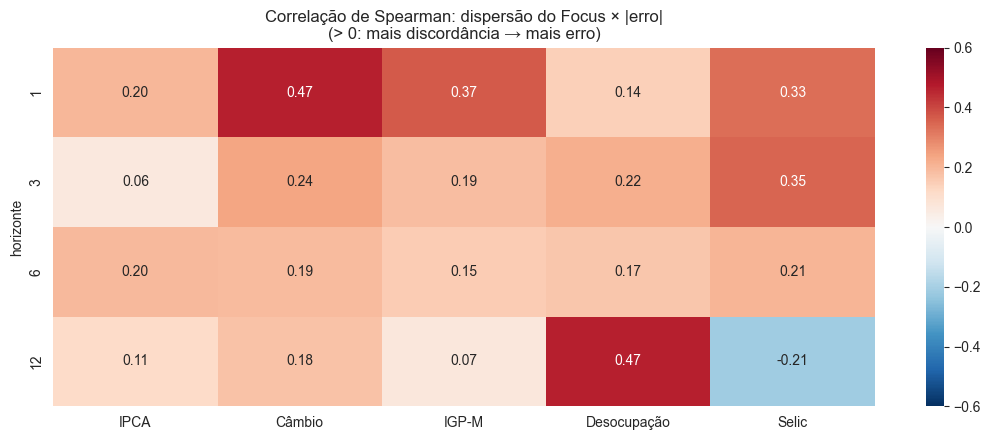

In [20]:
fig, ax = plt.subplots(figsize=(11, 4.5))
piv = tab_disp["Spearman ρ"].unstack("indicador")[[ROTULO[n] for n in ORDEM]]
sns.heatmap(piv, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, ax=ax)
ax.set_title("Correlação de Spearman: dispersão do Focus × |erro|\n(> 0: mais discordância → mais erro)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 9. Conclusões

**Sobre o ponto (primeiro momento):**
- O Focus **agrega valor** sobre "não prever mudança" em IPCA, Selic e IGP-M, em todos os horizontes.
- No **Câmbio**, converge ao passeio aleatório conforme o horizonte cresce (razão 0,64 → 0,99).
- O viés existe e cresce com o horizonte (IPCA: 0,044 → 0,083), concentrando-se em regimes de virada: o **aperto pós-COVID** lidera o viés em `h=12` tanto no IPCA (+0,34 p.p.) quanto na Selic (+5,1 p.p.), seguido de COVID e do choque inflacionário. Mas é **difícil de corrigir** com um modelo de média condicional (Etapa 4).

**Sobre a incerteza (segundo momento) — o achado central:**
- O intervalo construído com a dispersão publicada do Focus é **drasticamente estreito**: "90%" cobre tipicamente 25–55%.
- O problema **piora com o horizonte** nos cinco indicadores. É sobretudo de **escala** (o intervalo de 90% precisaria ser de 1,3 a 7,3 vezes mais largo, mediana ≈ 3,2×, com o pior caso no IGP-M de longo prazo), com um componente de **forma** na Selic de curto prazo (75,8% dos erros são exatamente zero).
- Discordância entre analistas **não** é incerteza da projeção — é uma fração dela.
- **Mas a dispersão não é inútil:** correlaciona positivamente com o erro absoluto em 19 das 20 combinações, significativamente em 13 (o tercil mais disperso erra 1,2× a 4,3× mais que o menos disperso). Ela ordena a incerteza *relativa* razoavelmente bem; erra na *escala*. A única exceção significativa é a Selic `h=12` (ρ = −0,21).

**Consequência para a Etapa 5.** Como a dispersão ordena bem a incerteza mas erra a escala, a alternativa mais simples — **reescalar o sigma por indicador × horizonte** — é um concorrente legítimo e precisa ser o baseline a bater. O que ela não resolve: (i) a **forma** (Selic de curto prazo, desocupação), (ii) a dependência de **regime** (o viés se concentra em viradas, e um fator constante ignora isso), e (iii) **garantia de cobertura** em amostra finita. É aí que quantis condicionais com calibração conformal teriam de justificar sua complexidade — e a Etapa 5 deve testar isso empiricamente, não assumi-lo.

**Ressalvas honestas:** a desocupação tem amostra de 214 linhas dominada por uma única tendência; os testes de Christoffersen em `h=12` têm poder limitado nas amostras menores; e o desvio-padrão do Focus é dispersão entre analistas de um mesmo mês, não uma medida de incerteza que o BCB pretenda publicar como tal.